<a href="https://colab.research.google.com/github/insight4healthlab/course-GS-HLTH-6270/blob/main/notebooks/Assignment_2_vision_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 Track B: medical vision
**Read `Assignment_2_Step_by_Step_Guide.docx` before running this notebook.** It contains the setup links, complete workflow, metric explanations, and troubleshooting instructions. Choose this track or the text track, not both. This guided notebook already contains the technical workflow. Your main tasks are to understand the steps, improve one prompt, run the experiment, and interpret the results. PneumoniaMNIST is for teaching only and is not intended for clinical use.

## Student checklist
Run the cells **one at a time, from top to bottom**. Do not use *Run all*.
1. Download and preview the fixed 10-image sample.
2. Connect securely and test one image.
3. Read the three prompts and make your one improvement to the advanced prompt.
4. Set `RUN_FULL_EXPERIMENT = True` and run the comparison (30 calls, about 3 minutes).
5. Run the supplied evaluation code.
6. Complete the five-image robustness check (5 calls).
7. Review five cases and write your conclusion.
8. Download your files and export the PDF.

Every place where you must write something is marked **Your answer**.

In [1]:
!pip -q install -U medmnist google-genai
import getpass, hashlib, json, os, re, time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google import genai
from google.genai import errors, types
from medmnist import PneumoniaMNIST
from sklearn.metrics import ConfusionMatrixDisplay

RANDOM_STATE = 6270
MODEL_NAME = "gemini-3.5-flash-lite"   # Fixed course model. Do not change.
MAX_OUTPUT_TOKENS = 1000
PREDICTIONS_FILE = "A2_vision_predictions.csv"
ROBUSTNESS_FILE = "A2_vision_robustness.csv"
CACHE_FILE = ".a2_vision_cache.json"
LABEL_NAMES = {0: "normal", 1: "pneumonia"}
DATA_ROOT = Path("medmnist_data")
DATA_ROOT.mkdir(exist_ok=True)
print("Setup complete.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.0.0 which is incompatible.
Setup complete.


## 1 Download the lightweight dataset
The notebook uses the 64-pixel teaching version because it is much smaller and more reliable to download than the 128- or 224-pixel files while retaining more image detail than the 28-pixel version. Each selected image is enlarged to 224 × 224 only for display and API input. If the server reports a temporary error, wait a few minutes and rerun this cell.

In [2]:
def load_test_data(attempts=4):
    for attempt in range(attempts):
        try:
            return PneumoniaMNIST(split="test", download=True, size=64, root=str(DATA_ROOT))
        except Exception:
            if attempt == attempts - 1:
                raise RuntimeError("The MedMNIST server is temporarily unavailable. Wait and rerun this cell.")
            time.sleep(2 ** attempt)

test_data = load_test_data()
print(f"Test images available: {len(test_data)}")

100%|██████████| 20.6M/20.6M [00:05<00:00, 3.87MB/s]

Test images available: 624


## 2 Create the fixed balanced 10-image sample
The code selects five normal and five pneumonia images. The same images are used for every prompt.

In [3]:
labels = np.asarray(test_data.labels).reshape(-1)
rng = np.random.default_rng(RANDOM_STATE)
selected = np.concatenate([
    rng.choice(np.where(labels == 0)[0], size=5, replace=False),
    rng.choice(np.where(labels == 1)[0], size=5, replace=False),
])
rng.shuffle(selected)   # mix the two classes so the first five cases are not all one label
records = []
for case_number, index in enumerate(selected, start=1):
    image, label = test_data[int(index)]
    enlarged = image.convert("RGB").resize((224, 224))
    records.append({
        "case_id": f"V{case_number:03d}",
        "source_index": int(index),
        "image": enlarged,
        "gold_label": LABEL_NAMES[int(np.asarray(label).reshape(-1)[0])],
    })
assert len(records) == 10
print(pd.Series([r["gold_label"] for r in records]).value_counts().to_string())

normal       5
pneumonia    5


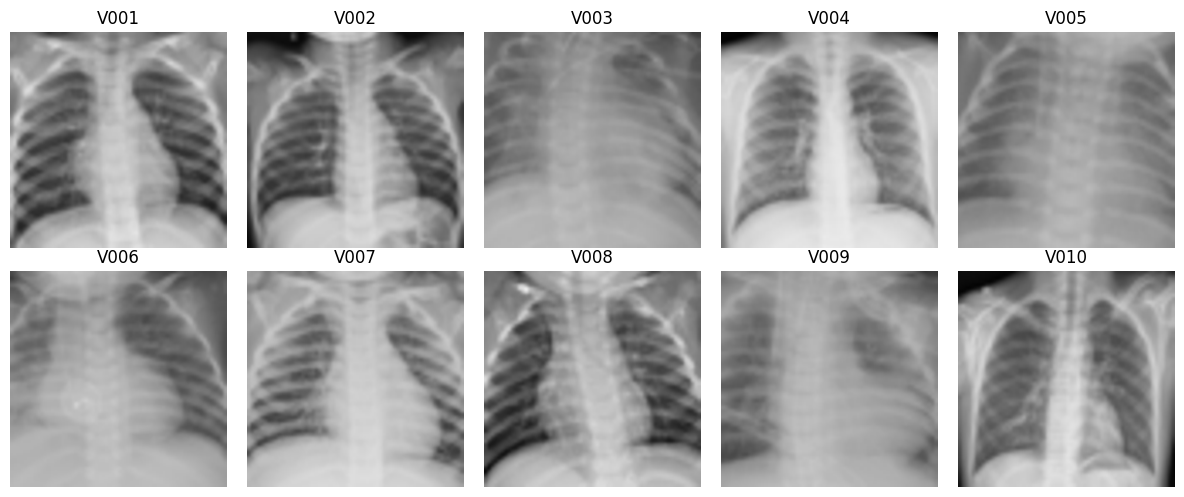

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for axis, record in zip(axes.ravel(), records):
    axis.imshow(record["image"], cmap="gray")
    axis.set_title(record["case_id"])
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3 Connect securely
Create your Gemini API key at https://aistudio.google.com/apikey (use a personal Google account if your university account is blocked). **In Google Colab:** click the key-shaped **Secrets** icon on the left, add a secret named `GEMINI_API_KEY`, paste your key as its value, and switch on **Notebook access**. Then run the cell below. If the secret is unavailable, the notebook asks you to paste the key into a hidden box. The key is never saved in the notebook. **Do not add billing or payment details** — the free tier is enough for this assignment. One image is sent per request.

In [5]:
def get_api_key():
    key = None
    try:
        from google.colab import userdata
        key = userdata.get("GEMINI_API_KEY")
    except Exception:
        key = os.getenv("GEMINI_API_KEY")
    if not key:
        key = getpass.getpass("Paste your Gemini API key (hidden): ").strip()
    if not key:
        raise RuntimeError("No API key was supplied. Ask the instructor for access help.")
    return key

client = genai.Client(api_key=get_api_key())

# Settings are the same for every request, so the prompts are compared fairly.
# Current Gemini models do not accept a custom temperature, and their "thinking"
# counts toward max_output_tokens, so the limit is generous. Do not change these.
GENERATION_CONFIG = types.GenerateContentConfig(
    max_output_tokens=MAX_OUTPUT_TOKENS,
    thinking_config=types.ThinkingConfig(thinking_level="low"),
)
RETRYABLE_CODES = {429, 500, 502, 503, 504}   # busy or rate-limited: worth waiting
SECONDS_BETWEEN_CALLS = 5                      # keeps the notebook under free-tier per-minute limits

def call_with_retry(contents, attempts=4):
    """Send one request. Wait and retry only for temporary errors."""
    for attempt in range(attempts):
        try:
            response = client.models.generate_content(
                model=MODEL_NAME, contents=contents, config=GENERATION_CONFIG)
            return response.text or ""
        except errors.APIError as exc:
            code = getattr(exc, "code", None)
            if code not in RETRYABLE_CODES or attempt == attempts - 1:
                raise
            wait = 20 * (attempt + 1)
            print(f"  Temporary error {code}. Waiting {wait} seconds, then retrying...")
            time.sleep(wait)

# Completed calls are remembered in a small file, so re-running a cell or
# reconnecting after a disconnect never repeats a call that already succeeded.
def _load_cache():
    if os.path.exists(CACHE_FILE):
        with open(CACHE_FILE) as handle:
            return json.load(handle)
    return {}

def cached_call(case_id, prompt_name, prompt_text, contents):
    """Return (raw_output, error). Uses the saved answer if this exact request was already made."""
    cache = _load_cache()
    key = f"{MODEL_NAME}|{prompt_name}|{case_id}|" + hashlib.sha1(prompt_text.encode()).hexdigest()
    if key in cache:
        return cache[key], ""
    try:
        raw = call_with_retry(contents)
    except Exception as exc:
        return "", f"{type(exc).__name__}: {exc}"[:300]
    finally:
        time.sleep(SECONDS_BETWEEN_CALLS)
    cache[key] = raw
    with open(CACHE_FILE, "w") as handle:
        json.dump(cache, handle)
    return raw, ""

print(f"Connection setup is ready. Model: {MODEL_NAME}")

Paste your Gemini API key (hidden): ··········
Connection setup is ready. Model: gemini-3.5-flash-lite


## 4 Read and improve the prompts
All three prompts work as written. **Before the full run**, make **one meaningful change** inside `prompt_advanced` (for example: a clearer rule, a short description of what to look for, or a stronger self-check). Leave `prompt_zero` and `prompt_structured` unchanged. The only permitted labels are `normal` and `pneumonia`. Then run the cell and explain your change in the answer cell below it.

In [6]:
def prompt_zero():
    return "Classify this teaching chest X-ray as normal or pneumonia. Return one label only."

def prompt_structured():
    return (
        "This is a labelled teaching image, not a clinical case. Choose exactly one label: "
        "normal or pneumonia. Return only the label in lowercase with no explanation."
    )

def prompt_advanced():
    # ---- Make your ONE change inside this function ----
    return (
        "Classify this labelled teaching chest X-ray. Allowed labels are normal and pneumonia. "
        "Silently check that your final answer contains exactly one allowed label. "
        "Do not infer identity, prognosis, or treatment. Return only the lowercase label."
    )

print("Prompts are defined. Your advanced prompt is:\n")
print(prompt_advanced())

Prompts are defined. Your advanced prompt is:

Classify this labelled teaching chest X-ray. Allowed labels are normal and pneumonia. Silently check that your final answer contains exactly one allowed label. Do not infer identity, prognosis, or treatment. Return only the lowercase label.


**What I changed in `prompt_advanced` and why I expect it to help (2–3 sentences)**

**Your answer:** *(double-click this cell, replace this text, then press Shift+Enter)*

## 5 Test one image
This makes only one API call. You should see `normal` or `pneumonia`. If you see an error instead, use the troubleshooting table in the guide before continuing.

In [7]:
first = records[0]
test_response, test_error = cached_call(first["case_id"], "zero", prompt_zero(), [prompt_zero(), first["image"]])
print(test_response if not test_error else f"ERROR - fix this before continuing:\n{test_error}")

pneumonia


## 6 Run the prompt comparison
With `RUN_FULL_EXPERIMENT = False` the cell tries each of the three prompts on **one** image (3 calls) so you can check that everything works. When it does, change `False` to `True` and run the cell again: it processes 10 images with three prompts, one image at a time (30 calls, about 3 minutes).

Each answer is saved as soon as it arrives. If the cell stops or Colab disconnects, rerun the notebook from the top and run this cell again — finished calls are not repeated.

If you edit `prompt_advanced` after the full run, run the prompt cell and this cell again: only the 10 advanced-prompt calls are repeated. Please do this at most once or twice.

In [13]:
def parse_label(raw):
    words = set(re.findall(r"[a-z]+", (raw or "").lower()))
    found = [label for label in ("normal", "pneumonia") if label in words]
    return found[0] if len(found) == 1 else None

def run_prompt(prompt_name, prompt_function, cases):
    out = []
    for record in cases:
        prompt_text = prompt_function()
        raw, error = cached_call(record["case_id"], prompt_name, prompt_text, [prompt_text, record["image"]])
        predicted = parse_label(raw)
        out.append({
            "case_id": record["case_id"], "source_index": record["source_index"], "prompt": prompt_name,
            "gold_label": record["gold_label"], "prediction": predicted,
            "raw_output": raw, "error": error, "valid_output": predicted is not None,
        })
        print(f"  {prompt_name:<11} {record['case_id']}: {'ERROR' if error else 'ok'}")
    return out

prompt_functions = {"zero": prompt_zero, "structured": prompt_structured, "advanced": prompt_advanced}
RUN_FULL_EXPERIMENT = False  # Change to True after the 3-call check works.
evaluation_records = records if RUN_FULL_EXPERIMENT else records[:1]
results = []
for prompt_name, prompt_function in prompt_functions.items():
    results += run_prompt(prompt_name, prompt_function, evaluation_records)
    pd.DataFrame(results).to_csv(PREDICTIONS_FILE, index=False)
predictions = pd.DataFrame(results)
n_errors = int((predictions["error"] != "").sum())
print(f"\nSaved {len(predictions)} rows to {PREDICTIONS_FILE}. Calls that failed with an error: {n_errors}")
if n_errors:
    print("Some calls failed. Wait a few minutes and run this cell again; only the failed calls are repeated.")
if not RUN_FULL_EXPERIMENT:
    print("This was only the 3-call check. Set RUN_FULL_EXPERIMENT = True and run this cell again.")
display(predictions.head(6))

  zero        V001: ok
  zero        V002: ok
  zero        V003: ok
  zero        V004: ok
  zero        V005: ok
  zero        V006: ok
  zero        V007: ok
  zero        V008: ok
  zero        V009: ok
  zero        V010: ok
  structured  V001: ok
  structured  V002: ok
  structured  V003: ok
  structured  V004: ok
  structured  V005: ok
  structured  V006: ok
  structured  V007: ok
  structured  V008: ok
  structured  V009: ok
  structured  V010: ok
  advanced    V001: ok
  advanced    V002: ok
  advanced    V003: ok
  advanced    V004: ok
  advanced    V005: ok
  advanced    V006: ok
  advanced    V007: ok
  advanced    V008: ok
  advanced    V009: ok
  advanced    V010: ok

Saved 30 rows to A2_vision_predictions.csv. Calls that failed with an error: 0


,case_id,source_index,prompt,gold_label,prediction,raw_output,error,valid_output
0,V001,485,zero,normal,pneumonia,pneumonia,,True
1,V002,460,zero,normal,pneumonia,pneumonia,,True
2,V003,156,zero,pneumonia,pneumonia,pneumonia,,True
3,V004,411,zero,normal,pneumonia,pneumonia,,True
4,V005,300,zero,pneumonia,pneumonia,pneumonia,,True
5,V006,379,zero,pneumonia,pneumonia,pneumonia,,True


## 7 Evaluate the three prompts
The code below is provided. Run it; do not rewrite it. An invalid output (no label, or both labels) counts as incorrect.

,accuracy_including_invalid,pneumonia_recall,invalid_output_rate
prompt,,,
zero,0.5,1.0,0.0
structured,0.6,1.0,0.0
advanced,0.5,1.0,0.0


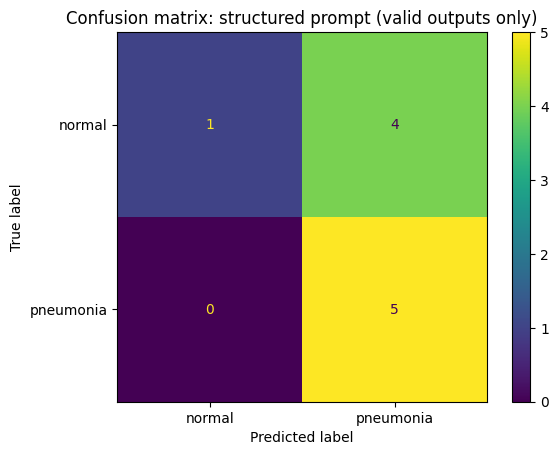

In [14]:
if not RUN_FULL_EXPERIMENT:
    print("NOTE: these numbers use ONE image only. Set RUN_FULL_EXPERIMENT = True in step 6 for your real results.\n")
metric_rows = []
for prompt_name in prompt_functions:
    group = predictions[predictions["prompt"] == prompt_name]
    is_pneumonia = group["gold_label"] == "pneumonia"
    metric_rows.append({
        "prompt": prompt_name,
        "accuracy_including_invalid": (group["prediction"] == group["gold_label"]).mean(),
        "pneumonia_recall": (group.loc[is_pneumonia, "prediction"] == "pneumonia").mean() if is_pneumonia.any() else float("nan"),
        "invalid_output_rate": 1 - group["valid_output"].mean(),
    })
metrics = pd.DataFrame(metric_rows).set_index("prompt")
display(metrics.round(3))
best_prompt = metrics["accuracy_including_invalid"].idxmax()
best = predictions[(predictions["prompt"] == best_prompt) & predictions["valid_output"]]
if len(best):
    ConfusionMatrixDisplay.from_predictions(best["gold_label"], best["prediction"], labels=["normal", "pneumonia"])
    plt.title(f"Confusion matrix: {best_prompt} prompt (valid outputs only)")
    plt.show()
else:
    print("No valid outputs were available for a confusion matrix.")

**Interpretation (4–6 sentences).** Which prompt performed best? Was pneumonia recall different from overall accuracy? Were invalid outputs a problem? Is the difference large enough to matter with only 10 images?

**Your answer:** *(double-click this cell, replace this text, then press Shift+Enter)*

## 8 Five-image robustness check
A robust system gives similar answers when the instruction is reworded without changing its meaning. (The model can also vary slightly between identical requests, so interpret one changed answer cautiously.)
1. In the cell below, change the rewording line so the instruction says the same thing in different words.
2. Write your prediction in the answer cell **before** running.
3. Set `RUN_ROBUSTNESS = True` and run. This adds five calls on the first five images.

**My prediction before running (1 sentence)**

**Your answer:** *(double-click this cell, replace this text, then press Shift+Enter)*

In [15]:
def prompt_reworded():
    # ---- Edit the line below: reword the instruction, keep the same two allowed labels ----
    return prompt_advanced().replace("Classify this labelled teaching chest X-ray.",
                                     "Decide which label fits this labelled teaching chest X-ray.")

RUN_ROBUSTNESS = False  # Change to True when ready; this adds five calls.
if RUN_ROBUSTNESS and not RUN_FULL_EXPERIMENT:
    print("Finish step 6 with RUN_FULL_EXPERIMENT = True first.")
elif RUN_ROBUSTNESS:
    assert prompt_reworded() != prompt_advanced(), \
        "Your reworded prompt is identical to the advanced prompt. Edit prompt_reworded first."
    robustness = pd.DataFrame(run_prompt("reworded", prompt_reworded, records[:5]))
    robustness.to_csv(ROBUSTNESS_FILE, index=False)
    original = predictions[predictions["prompt"] == "advanced"].set_index("case_id")["prediction"]
    comparison = robustness.set_index("case_id")[["gold_label", "prediction"]].rename(columns={"prediction": "reworded"})
    comparison.insert(1, "advanced", original)
    comparison["same_answer"] = comparison["advanced"].fillna("<invalid>") == comparison["reworded"].fillna("<invalid>")
    display(comparison)
    print(f"Answers that stayed the same after rewording: {int(comparison['same_answer'].sum())} of {len(comparison)}")
    print(f"Saved {ROBUSTNESS_FILE}")
else:
    print("Robustness check not run yet. Set RUN_ROBUSTNESS = True when ready.")

Robustness check not run yet. Set RUN_ROBUSTNESS = True when ready.


**What happened (2–3 sentences).** Were the outputs stable? Give one concrete example (case ID).

**Your answer:** *(double-click this cell, replace this text, then press Shift+Enter)*

## 9 Review five cases
Run the cell to list invalid and wrong outputs first. Pick five rows, look at the image in the preview above, and complete the table below. If there are fewer than five errors, include correct cases and explain why they succeeded.

In [16]:
review = predictions.copy()
review["correct"] = review["prediction"] == review["gold_label"]
review = review.sort_values(["valid_output", "correct"])
print(f"Wrong or invalid rows: {(~review['correct']).sum()} of {len(review)}")
display(review.head(10))

Wrong or invalid rows: 14 of 30


,case_id,source_index,prompt,gold_label,prediction,raw_output,error,valid_output,correct
0,V001,485,zero,normal,pneumonia,pneumonia,,True,False
1,V002,460,zero,normal,pneumonia,pneumonia,,True,False
3,V004,411,zero,normal,pneumonia,pneumonia,,True,False
7,V008,179,zero,normal,pneumonia,pneumonia,,True,False
9,V010,187,zero,normal,pneumonia,pneumonia,,True,False
10,V001,485,structured,normal,pneumonia,pneumonia,,True,False
11,V002,460,structured,normal,pneumonia,pneumonia,,True,False
13,V004,411,structured,normal,pneumonia,pneumonia,,True,False
17,V008,179,structured,normal,pneumonia,pneumonia,,True,False
20,V001,485,advanced,normal,pneumonia,pneumonia,,True,False


| Case ID | Prompt | Reference | Prediction | What happened? | Failure type | Possible risk |
|---|---|---|---|---|---|---|
| *V000 (example)* | *zero* | *pneumonia* | *normal* | *Model missed a pneumonia image* | *Wrong label* | *A missed case could delay treatment* |
|  |  |  |  |  |  |  |
|  |  |  |  |  |  |  |
|  |  |  |  |  |  |  |
|  |  |  |  |  |  |  |
|  |  |  |  |  |  |  |

Failure types: wrong label, invalid format, omission, unsupported claim, or correct.

## 10 Conclusion and tool-use declaration
In 150–250 words: (1) identify the best prompt and cite one or two metric values, (2) describe one important error or robustness finding, (3) say whether you would trust the system for this limited teaching task, (4) name at least one safeguard, and (5) state that the results do not establish clinical validity.

**Your answer:** *(double-click this cell, replace this text, then press Shift+Enter)*

**Tool-use declaration** (replace the example row; write "None" if you used no tools)

| Tool (AI, coding, translation, editing) | What I used it for | How I checked its output |
|---|---|---|
| *Example: Grammarly* | *Grammar check of my conclusion* | *Re-read every suggested change* |

## 11 Download your files and export the PDF
1. Run the cell below to download your CSV files (Colab storage is temporary).
2. **File → Download → Download .ipynb** to save the executed notebook.
3. **File → Print → Save as PDF** to create the PDF. Check that the PDF shows your outputs and written answers.
4. Check that your API key does not appear anywhere. Submit the .ipynb, the PDF, and both CSV files.

In [ ]:
for name in [PREDICTIONS_FILE, ROBUSTNESS_FILE]:
    if not os.path.exists(name):
        print(f"{name} does not exist yet - complete that step first.")
        continue
    try:
        from google.colab import files
        files.download(name)
    except ImportError:
        print(f"Saved: {name}")

Dataset: PneumoniaMNIST, MedMNIST v3.0, CC BY 4.0. Official record: https://zenodo.org/records/10519652. This small teaching sample is not a clinical-performance estimate and is not intended for clinical use.